# Stage 6 - Figures and tables for the paper

Every figure and table in the paper, made from the saved outputs of stages 2 to 5. No model is fitted here:
this notebook reads the saved outputs, summarises them and plots them. Some figures and tables are extra and may not be used in the paper.

- **Input:** `data/processed/`, and `data/raw/alfred_vintages.csv` for the data table
- **Output:** `figures/*.pdf` (figures), `tables/*.tex` (tables included by the paper) and `tables/*.csv` (same numbers)

Run from top to bottom in a fresh kernel (about 20 seconds).

In [1]:
# the notebook needs code/ as working directory to import config and helpers:
# VS Code starts there, JupyterLab on Nuvolos starts in /files, so look for the project
import os
from pathlib import Path

if not Path("helpers.py").exists():
    found = [p.parent for p in Path.cwd().glob("**/code/01_get_data.py") if (p.parent / "helpers.py").exists()]
    if len(found) != 1:
        raise FileNotFoundError(f"cannot find a single project code folder under {Path.cwd()}: {found}")
    os.chdir(found[0])
print("working directory:", Path.cwd())

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import config
import helpers

plt.rcParams.update({
    "font.family": "serif", "font.size": 8.5, "axes.titlesize": 8.5, "axes.labelsize": 8.5,
    "legend.fontsize": 7.5, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.6,
    "axes.grid": True, "grid.color": "#e3e3e0", "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.2, "legend.frameon": False, "savefig.dpi": 300,
})
WIDTH = 5.2    # inches, the text width of the SIAM article class

# fixed colour per series, the same in every figure
BLUE, ORANGE, AQUA, YELLOW, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"
GREY, DARK = "#8c8c88", "#3d3d3a"

working directory: /Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/code


## Data

In [2]:
def load(name, **kw):
    return helpers.load_processed(name, **kw)


sb = load("stock_bond_corr", index_col="date", parse_dates=True)
macro_rt = load("macro_realtime_12m", index_col="date", parse_dates=True)
macro_rev = load("macro_revised_12m", index_col="date", parse_dates=True)
baseline = load("baseline_regimes", index_col="date", parse_dates=True)
pca_scores = load("pca_scores", index_col="date", parse_dates=True)
loadings = load("pca_loadings_full", index_col="indicator")
separation = load("regimes_separation", index_col=[0, 1, 2])
separation_idx = load("regimes_idx_separation", index_col=[0, 1, 2])
perf4 = load("portfolio_performance", index_col=[0, 1, 2]).sort_index()
returns4 = load("portfolio_returns", index_col="date", parse_dates=True)
positions4 = load("portfolio_positions", index_col=[0, 1], parse_dates=["date"])
accuracy = load("forecast_accuracy", index_col=[0, 1])
perf5 = load("forecast_performance", index_col=[0, 1]).sort_index()
predictions = load("forecast_predictions", index_col="date", parse_dates=True)
importance = load("forecast_importance", index_col="feature")
rf = load("riskfree_monthly", index_col="date", parse_dates=True)["rf"]

## Table helper

Tables are written as LaTeX `tabular` blocks (booktabs rules); the caption and label are in the paper.

In [3]:
def latex_text(x):
    """Escape the characters LaTeX treats as special; a leading minus sign becomes a proper minus."""
    x = str(x)
    for a, b in [("\\", r"\textbackslash{}"), ("&", r"\&"), ("%", r"\%"), ("_", r"\_"), ("#", r"\#")]:
        x = x.replace(a, b)
    return x


def save_latex(df, name, formats, index_name="", col_names=None, groups=None, top=None):
    """
    Write df to tables/<name>.tex as a booktabs tabular, and to tables/<name>.csv.
    formats: {column: format string or function}; col_names: header text per column (LaTeX allowed);
    groups: list of (label, first row position) to start a block of rows with a small heading;
    top: list of (label, number of columns) for a header row above the column names.
    """
    helpers.save_table(df, name)
    cols = list(df.columns)
    align = "l" + "".join("l" if df[c].dtype == object else "r" for c in cols)
    lines = [r"\begin{tabular}{" + align + "}", r"\toprule"]
    if top:
        cells, rules, start = [""], [], 2
        for label, span in top:
            cells.append(r"\multicolumn{%d}{c}{%s}" % (span, label) if label else " & ".join([""] * span))
            if label:
                rules.append(r"\cmidrule(lr){%d-%d}" % (start, start + span - 1))
            start += span
        lines += [" & ".join(cells) + r" \\", " ".join(rules)]
    header = [index_name] + [(col_names or {}).get(c, latex_text(c)) for c in cols]
    lines += [" & ".join(header) + r" \\", r"\midrule"]
    starts = dict((pos, label) for label, pos in (groups or []))
    for i, (idx, row) in enumerate(df.iterrows()):
        if i in starts:
            if i > 0:
                lines.append(r"\addlinespace")
            lines.append(r"\multicolumn{%d}{l}{\emph{%s}} \\" % (len(cols) + 1, starts[i]))
        cells = [latex_text(idx) if "$" not in str(idx) else str(idx)]
        for c in cols:
            v, f = row[c], formats.get(c, "{:.2f}")
            if pd.isna(v):
                cells.append("--")
                continue
            text = f(v) if callable(f) else f.format(v)
            if isinstance(v, str):
                text = latex_text(text)
            elif text.startswith("-"):
                text = "$-$" + text[1:]
            cells.append(text)
        lines.append(" & ".join(cells) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    config.TABLES.mkdir(parents=True, exist_ok=True)
    (config.TABLES / f"{name}.tex").write_text("\n".join(lines) + "\n")
    print(f"saved tables/{name}.tex: {len(df)} rows")


def pct(v, digits=1):
    return f"{100 * v:.{digits}f}"


def pval(v):
    return "$<$0.001" if v < 0.001 else f"{v:.3f}"


STRATEGY_NAMES = {
    "60_40": "60/40", "60_40 (stage 4)": "60/40",
    "rp_unconditional": "RP, static", "rp_rolling": "RP, 12-month",
    "rp_quadrants": "RP, quadrants", "rp_gmm": "RP, GMM regimes",
    "rp_quadrants_revised": "RP, quadrants (rev.)", "rp_gmm_revised": "RP, GMM (rev.)",
    "rp_oracle": "RP, perfect foresight",
    "historical_mean": "Historical mean", "last_month": "Last month", "rolling_12m": "12-month average",
    "ols_all": "Linear regression", "ridge_market": "Ridge, market", "ridge_all": "Ridge, all",
    "forest_market": "Random forest, market", "forest_all": "Random forest, all",
    "boosting_market": "Boosting, market", "boosting_all": "Boosting, all",
    "oracle_spy_tlt": "Perfect foresight",
}

## Table 1 - The macro data

In [4]:
vintages = helpers.load_alfred_vintages()
first_vintage = vintages.groupby("series_id")["realtime_start"].min()
n_vintages = vintages.groupby("series_id")["realtime_start"].nunique()
columns = {"INDPRO": "indpro", "TCU": "tcu", "RRSFS": "retail", "HOUST": "housing", "PAYEMS": "payrolls",
           "UNRATE": "unrate", "ICSA": "claims", "CPIAUCSL": "cpi", "CPILFESL": "core_cpi", "PPIACO": "ppi"}
transform = {"TCU": "level", "UNRATE": "change"}
short = {"INDPRO": "Industrial production", "TCU": "Capacity utilisation", "RRSFS": "Real retail sales",
         "HOUST": "Housing starts", "PAYEMS": "Nonfarm payrolls", "UNRATE": "Unemployment rate",
         "ICSA": "Initial jobless claims", "CPIAUCSL": "CPI, all items", "CPILFESL": "CPI, core",
         "PPIACO": "PPI, all commodities"}
revision = (macro_rt - macro_rev).loc["2006":].abs().mean()

rows = {}
for sid, col in columns.items():
    block, desc, _, _ = config.MACRO_SERIES[sid]
    rows[sid] = {"block": block, "description": short[sid],
                 "transformation": transform.get(sid, "log change"),
                 "first vintage": first_vintage[sid][:7], "vintages": n_vintages[sid],
                 "revision": revision[col]}
data_table = pd.DataFrame(rows).T
data_table[["vintages", "revision"]] = data_table[["vintages", "revision"]].astype(float)
save_latex(data_table, "tab_data",
           {"block": "{}", "description": "{}", "transformation": "{}", "first vintage": "{}",
            "vintages": "{:,.0f}", "revision": "{:.2f}"},
           index_name="Series",
           col_names={"block": "Block", "description": "Description", "transformation": "Transformation",
                      "first vintage": "First vint.", "vintages": "Vintages", "revision": "Revision"})
data_table

saved tables/tab_data.tex: 10 rows


,block,description,transformation,first vintage,vintages,revision
INDPRO,growth,Industrial production,log change,1990-02,466.0,1.145218
TCU,growth,Capacity utilisation,level,1996-11,385.0,1.031278
RRSFS,growth,Real retail sales,log change,2001-06,494.0,0.605380
HOUST,growth,Housing starts,log change,1990-02,435.0,2.322819
PAYEMS,labour,Nonfarm payrolls,log change,1990-02,441.0,0.225881
UNRATE,labour,Unemployment rate,change,1990-02,440.0,0.045565
ICSA,labour,Initial jobless claims,log change,2009-05,899.0,1.309765
CPIAUCSL,inflation,"CPI, all items",log change,1990-02,458.0,0.029764
CPILFESL,inflation,"CPI, core",log change,1996-12,376.0,0.018668
PPIACO,inflation,"PPI, all commodities",log change,1996-12,367.0,0.143798


## Figure 1 - The stock-bond correlation and inflation

PosixPath('/Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/figures/fig_correlation.pdf')

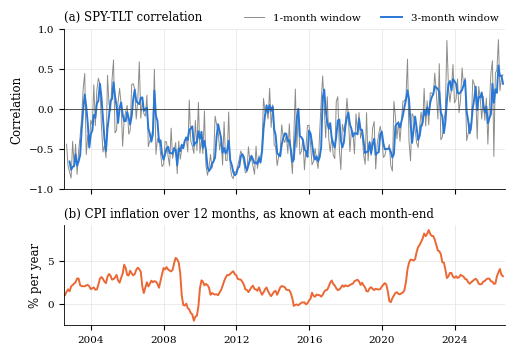

In [5]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(WIDTH, 3.6), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
ax1.plot(sb.index, sb["spy_tlt_corr"], color=GREY, lw=0.7, label="1-month window")
ax1.plot(sb.index, sb["spy_tlt_corr_3m"], color=BLUE, lw=1.4, label="3-month window")
ax1.axhline(0, color=DARK, lw=0.6)
ax1.set_ylabel("Correlation")
ax1.set_ylim(-1, 1)
ax1.legend(loc="lower right", bbox_to_anchor=(1, 1.0), borderaxespad=0.2, ncol=2)
ax1.set_title("(a) SPY-TLT correlation", loc="left")

cpi = macro_rt["cpi"].loc["2002-07":]
ax2.plot(cpi.index, cpi, color=ORANGE, lw=1.4)
ax2.set_ylabel("% per year")
ax2.set_title("(b) CPI inflation over 12 months, as known at each month-end", loc="left")
ax2.set_xlim(pd.Timestamp("2002-07-01"), pd.Timestamp("2026-09-30"))
fig.tight_layout()
helpers.save_figure(fig, "fig_correlation")

## Figure 2 - Real-time and revised data: the first factor in 2006-2026

PosixPath('/Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/figures/fig_realtime_revised.pdf')

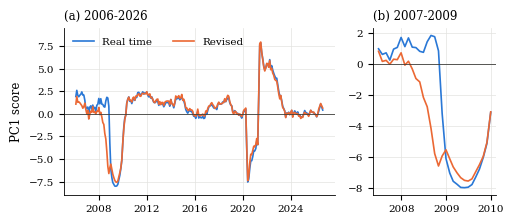

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(WIDTH, 2.3), gridspec_kw={"width_ratios": [2.2, 1]})
for ax, (a, b) in [(ax1, ("2006", "2026")), (ax2, ("2007-06", "2009-12"))]:
    ax.plot(pca_scores.loc[a:b].index, pca_scores.loc[a:b, "realtime_12m_pc1"], color=BLUE, label="Real time")
    ax.plot(pca_scores.loc[a:b].index, pca_scores.loc[a:b, "revised_12m_pc1"], color=ORANGE, label="Revised")
    ax.axhline(0, color=DARK, lw=0.6)
ax1.set_ylabel("PC1 score")
ax1.set_title("(a) 2006-2026", loc="left")
ax2.set_title("(b) 2007-2009", loc="left")
ax2.xaxis.set_major_locator(plt.matplotlib.dates.YearLocator())
ax2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Y"))
ax1.legend(loc="upper left", ncol=2)
ax1.set_ylim(-9, 9.5)
fig.tight_layout()
helpers.save_figure(fig, "fig_realtime_revised")

## Figure 3 - What the factors mean (full-sample loadings, real time, 12-month changes)

PosixPath('/Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/figures/fig_loadings.pdf')

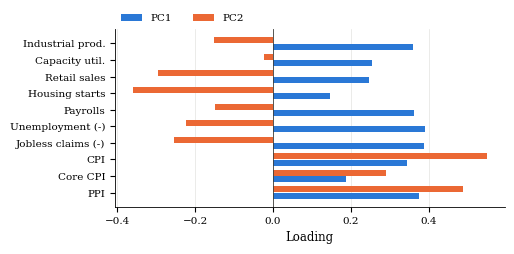

In [7]:
names = {"indpro": "Industrial prod.", "tcu": "Capacity util.", "retail": "Retail sales", "housing": "Housing starts",
         "payrolls": "Payrolls", "unrate": "Unemployment (-)", "claims": "Jobless claims (-)", "cpi": "CPI",
         "core_cpi": "Core CPI", "ppi": "PPI"}
L = loadings[["realtime_12m_pc1", "realtime_12m_pc2"]].rename(index=names)
y = np.arange(len(L))
fig, ax = plt.subplots(figsize=(WIDTH, 2.6))
ax.barh(y + 0.19, L["realtime_12m_pc1"], height=0.36, color=BLUE, label="PC1")
ax.barh(y - 0.19, L["realtime_12m_pc2"], height=0.36, color=ORANGE, label="PC2")
ax.set_yticks(y, L.index)
ax.invert_yaxis()
ax.axvline(0, color=DARK, lw=0.6)
ax.set_xlabel("Loading")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, borderaxespad=0.2)
fig.tight_layout()
helpers.save_figure(fig, "fig_loadings")

## Table 2 - Correlation after each quadrant

In [8]:
target_3m = sb["spy_tlt_corr_3m"].shift(-3, freq="ME")   # correlation over months t+1 to t+3, as in stage 3
rows = []
for data in ["realtime", "revised"]:
    q = baseline[f"{data}_quadrant"]
    df = pd.DataFrame({"quadrant": q, "next": target_3m.reindex(q.index)}).dropna()
    g = df.groupby("quadrant")["next"]
    t = pd.DataFrame({"months": g.size(), "mean": g.mean(), "positive": g.apply(lambda x: (x > 0).mean())})
    t.index = [f"{i.capitalize()}" for i in t.index]
    rows.append(t.reindex(["Goldilocks", "Overheating", "Slowdown", "Stagflation"]))
quad_table = pd.concat(rows, axis=1, keys=["realtime", "revised"])
quad_table.columns = [f"{a} {b}" for a, b in quad_table.columns]
save_latex(quad_table, "tab_quadrants",
           {c: ("{:.0f}" if "months" in c else ("{:.2f}" if "mean" in c else pct)) for c in quad_table.columns},
           index_name="Quadrant",
           col_names={c: {"months": "Months", "mean": "Mean", "positive": r"\% $>0$"}[c.split()[1]]
                      for c in quad_table.columns},
           top=[("Real-time data", 3), ("Revised data", 3)])
quad_table.round(2)

saved tables/tab_quadrants.tex: 4 rows


,realtime months,realtime mean,realtime positive,revised months,revised mean,revised positive
Goldilocks,53,-0.42,0.08,47,-0.42,0.09
Overheating,48,-0.29,0.23,48,-0.32,0.19
Slowdown,51,-0.33,0.10,53,-0.34,0.09
Stagflation,93,-0.12,0.39,97,-0.12,0.39


## Figure 4 and Table 3 - Do the regimes separate the correlation?

saved tables/tab_separation.tex: 11 rows


,R2 3m,p 3m,R2 1m,p 1m,R2 3m revised
Quadrants,0.144,0.003,0.109,0.003,0.150
"PCA + GMM, $k=3$ (main)",0.003,0.517,0.008,0.213,0.009
"PCA + K-Means, $k=3$",0.024,0.412,0.013,0.415,0.028
"PCA + GMM, $k=2$",0.038,0.042,0.007,0.297,0.000
"PCA + GMM, $k=4$",0.263,0.000,0.165,0.000,0.080
"PCA, 3-month changes + GMM, $k=3$",0.187,0.000,0.129,0.000,0.103
"PCA + CPI level + GMM, $k=3$",0.117,0.002,0.065,0.009,0.051
"Indices + GMM, $k=2$ (BIC)",0.001,0.730,0.001,0.756,0.004
"Indices + GMM, $k=4$",0.128,0.013,0.073,0.033,0.105
"Indices + K-Means, $k=4$",0.117,0.016,0.086,0.015,0.164


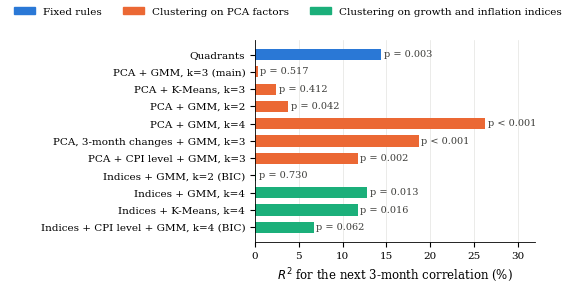

In [9]:
RUNS = [  # (label, table, run, method, family)
    ("Quadrants", separation, "realtime quadrants", "rules", "rules"),
    ("PCA + GMM, $k=3$ (main)", separation, "realtime_12m_k3", "gmm", "pca"),
    ("PCA + K-Means, $k=3$", separation, "realtime_12m_k3", "kmeans", "pca"),
    ("PCA + GMM, $k=2$", separation, "realtime_12m_k2", "gmm", "pca"),
    ("PCA + GMM, $k=4$", separation, "realtime_12m_k4", "gmm", "pca"),
    ("PCA, 3-month changes + GMM, $k=3$", separation, "realtime_3m_k3", "gmm", "pca"),
    ("PCA + CPI level + GMM, $k=3$", separation, "realtime_12m_cpi_k3", "gmm", "pca"),
    ("Indices + GMM, $k=2$ (BIC)", separation_idx, "realtime_idx_k2", "gmm", "idx"),
    ("Indices + GMM, $k=4$", separation_idx, "realtime_idx_k4", "gmm", "idx"),
    ("Indices + K-Means, $k=4$", separation_idx, "realtime_idx_k4", "kmeans", "idx"),
    ("Indices + CPI level + GMM, $k=4$ (BIC)", separation_idx, "realtime_idx_cpi_k4", "gmm", "idx"),
]
rows = {}
for label, table, run, method, family in RUNS:
    r = {"family": family}
    for target in ["3m", "1m"]:
        r[f"R2 {target}"] = float(table.loc[(target, run, method), "R2"])
        r[f"p {target}"] = float(table.loc[(target, run, method), "Wald p"])
        rev = run.replace("realtime", "revised")
        r[f"R2 {target} revised"] = float(table.loc[(target, rev, method), "R2"])
    rows[label] = r
sep = pd.DataFrame(rows).T
sep_out = sep[["R2 3m", "p 3m", "R2 1m", "p 1m", "R2 3m revised"]].astype(float)
save_latex(sep_out, "tab_separation",
           {"R2 3m": pct, "p 3m": pval, "R2 1m": pct, "p 1m": pval, "R2 3m revised": pct},
           index_name="Regimes (real time)",
           col_names={"R2 3m": r"$R^2$ (\%)", "p 3m": "$p$", "R2 1m": r"$R^2$ (\%)", "p 1m": "$p$",
                      "R2 3m revised": r"$R^2$ (\%)"},
           top=[("Next 3 months", 2), ("Next month", 2), ("Revised, 3 m.", 1)])

colours = {"rules": BLUE, "pca": ORANGE, "idx": AQUA}
fig, ax = plt.subplots(figsize=(WIDTH, 2.9))
yy = np.arange(len(sep))
ax.barh(yy, 100 * sep["R2 3m"].astype(float), color=[colours[f] for f in sep["family"]], height=0.65)
for i, (v, p) in enumerate(zip(sep["R2 3m"].astype(float), sep["p 3m"].astype(float))):
    ax.text(100 * v + 0.3, i, ("p < 0.001" if p < 0.001 else f"p = {p:.3f}"), va="center", fontsize=7, color=DARK)
ax.set_yticks(yy, [s.replace("$", "") for s in sep.index])
ax.invert_yaxis()
ax.set_xlabel(r"$R^2$ for the next 3-month correlation (%)")
ax.set_xlim(0, 32)
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colours.values()]
fig.legend(handles, ["Fixed rules", "Clustering on PCA factors", "Clustering on growth and inflation indices"],
           loc="upper center", ncol=3, borderaxespad=0.3)
fig.tight_layout(rect=(0, 0, 1, 0.93))
helpers.save_figure(fig, "fig_separation")
sep_out.round(3)

## Figure 5 - The quadrants over time, and the correlation that followed

PosixPath('/Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/figures/fig_quadrant_timeline.pdf')

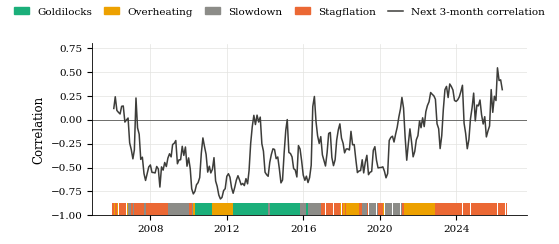

In [10]:
q = baseline["realtime_quadrant"]
qcol = {"goldilocks": AQUA, "overheating": YELLOW, "slowdown": GREY, "stagflation": ORANGE}
fig, ax = plt.subplots(figsize=(WIDTH, 2.4))
for d, lab in q.dropna().items():
    ax.axvspan(d - pd.offsets.MonthBegin(1), d, ymin=0, ymax=0.07, color=qcol[lab], lw=0)
nxt = target_3m.reindex(q.index)
ax.plot(nxt.index, nxt, color=DARK, lw=1.1, label="Correlation over the next 3 months")
ax.axhline(0, color=DARK, lw=0.5)
ax.set_ylim(-1, 0.8)
ax.set_ylabel("Correlation")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in qcol.values()]
fig.legend(handles + [ax.lines[0]], [k.capitalize() for k in qcol] + ["Next 3-month correlation"],
           loc="upper center", ncol=5, borderaxespad=0.3, columnspacing=1.2, handlelength=1.4)
fig.tight_layout(rect=(0, 0, 1, 0.9))
helpers.save_figure(fig, "fig_quadrant_timeline")

## Table 4 - Portfolios of stage 4, full sample

In [11]:
order4 = ["60_40", "rp_unconditional", "rp_rolling", "rp_quadrants", "rp_gmm", "rp_quadrants_revised",
          "rp_gmm_revised", "rp_oracle"]
excess4 = returns4[order4].sub(rf.reindex(returns4.index), axis=0)
tests = {s: helpers.sharpe_diff_test(excess4[s], excess4["rp_unconditional"])["p"]
         for s in order4 if s != "rp_unconditional"}
p4 = perf4.loc[("levered", "full sample")].loc[order4].copy()
p4["p vs static"] = pd.Series(tests)
p4.index = [STRATEGY_NAMES[s] for s in p4.index]
port_table = p4[["excess return", "volatility", "sharpe", "p vs static", "max drawdown", "turnover per year",
                 "average exposure"]]
save_latex(port_table, "tab_portfolios",
           {"excess return": pct, "volatility": pct, "sharpe": "{:.3f}", "p vs static": pval,
            "max drawdown": pct, "turnover per year": "{:.2f}", "average exposure": "{:.2f}"},
           index_name="Strategy",
           col_names={"excess return": r"Excess (\%)", "volatility": r"Vol. (\%)", "sharpe": "Sharpe",
                      "p vs static": "$p$", "max drawdown": r"Max DD (\%)", "turnover per year": "Turn.",
                      "average exposure": "Lev."})
port_table.round(3)

saved tables/tab_portfolios.tex: 8 rows


,excess return,volatility,sharpe,p vs static,max drawdown,turnover per year,average exposure
60/40,0.069,0.104,0.663,0.910,-0.285,0.317,1.000
"RP, static",0.073,0.107,0.684,NaN,-0.167,1.921,1.356
"RP, 12-month",0.073,0.107,0.684,0.986,-0.177,1.978,1.358
"RP, quadrants",0.074,0.107,0.691,0.501,-0.165,1.983,1.358
"RP, GMM regimes",0.073,0.107,0.682,0.704,-0.166,1.955,1.364
"RP, quadrants (rev.)",0.074,0.107,0.689,0.735,-0.169,2.002,1.361
"RP, GMM (rev.)",0.073,0.108,0.681,0.625,-0.167,1.929,1.358
"RP, perfect foresight",0.100,0.112,0.890,0.001,-0.169,4.432,1.434


## Table 5 - Sub-periods (excess return over cash, % per year)

In [12]:
periods = ["2007-2016", "2017-2026", "2008", "2020", "2022"]
sub = pd.DataFrame({p: perf4.loc[("levered", p)].loc[order4, "excess return"] for p in periods})
sub.index = [STRATEGY_NAMES[s] for s in sub.index]
save_latex(sub, "tab_subperiods", {p: pct for p in periods}, index_name="Strategy")
sub_sharpe = pd.DataFrame({p: perf4.loc[("levered", p)].loc[order4, "sharpe"] for p in ["full sample"] + periods})
sub_sharpe.index = [STRATEGY_NAMES[s] for s in sub_sharpe.index]
save_latex(sub_sharpe, "tab_subperiods_sharpe", {p: "{:.2f}" for p in sub_sharpe.columns}, index_name="Strategy")
sub.round(3)

saved tables/tab_subperiods.tex: 8 rows
saved tables/tab_subperiods_sharpe.tex: 8 rows


,2007-2016,2017-2026,2008,2020,2022
60/40,0.070,0.068,-0.146,0.187,-0.268
"RP, static",0.065,0.082,-0.017,0.048,-0.138
"RP, 12-month",0.066,0.081,-0.021,0.026,-0.110
"RP, quadrants",0.065,0.083,-0.019,0.039,-0.143
"RP, GMM regimes",0.065,0.082,-0.020,0.036,-0.139
"RP, quadrants (rev.)",0.066,0.082,-0.020,0.037,-0.144
"RP, GMM (rev.)",0.064,0.083,-0.018,0.043,-0.131
"RP, perfect foresight",0.083,0.117,-0.019,0.098,-0.082


## Table 6 - Robustness of stage 4: costs and no leverage (Sharpe ratio, full sample)

In [13]:
unlev = perf4.loc[("unlevered", "full sample")].loc[order4, "sharpe"]
costs = pd.DataFrame({"10 bps, levered": perf4.loc[("levered", "full sample")].loc[order4, "sharpe"],
                      "10 bps, no leverage": unlev})
costs.index = [STRATEGY_NAMES[s] for s in costs.index]
save_latex(costs, "tab_robustness", {c: "{:.3f}" for c in costs.columns}, index_name="Strategy")
costs.round(3)

saved tables/tab_robustness.tex: 8 rows


,"10 bps, levered","10 bps, no leverage"
60/40,0.663,0.663
"RP, static",0.684,0.671
"RP, 12-month",0.684,0.689
"RP, quadrants",0.691,0.675
"RP, GMM regimes",0.682,0.660
"RP, quadrants (rev.)",0.689,0.673
"RP, GMM (rev.)",0.681,0.673
"RP, perfect foresight",0.890,0.775


## Figure 6 - Wealth and drawdowns

PosixPath('/Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/figures/fig_wealth.pdf')

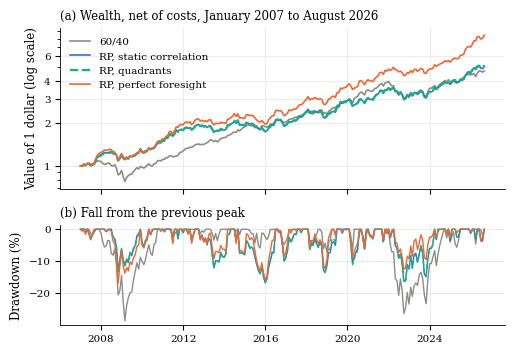

In [14]:
show = {"60_40": (GREY, "60/40"), "rp_unconditional": (BLUE, "RP, static correlation"),
        "rp_quadrants": (AQUA, "RP, quadrants"), "rp_oracle": (ORANGE, "RP, perfect foresight")}
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(WIDTH, 3.6), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
for s, (c, lab) in show.items():
    wealth = (1 + returns4[s]).cumprod()
    start = pd.Series([1.0], index=[returns4.index[0] - pd.offsets.MonthEnd(1)])
    wealth = pd.concat([start, wealth])
    ax1.plot(wealth.index, wealth, color=c, label=lab, lw=1.6 if s == "rp_quadrants" else 1.2,
             ls="--" if s == "rp_quadrants" else "-")
    ax2.plot(wealth.index, 100 * (wealth / wealth.cummax() - 1), color=c, lw=1.0,
             ls="--" if s == "rp_quadrants" else "-")
ax1.set_yscale("log")
ax1.set_yticks([1, 2, 3, 4, 6], ["1", "2", "3", "4", "6"])
ax1.set_ylabel("Value of 1 dollar (log scale)")
ax1.legend(loc="upper left")
ax1.set_title("(a) Wealth, net of costs, January 2007 to August 2026", loc="left")
ax2.set_ylabel("Drawdown (%)")
ax2.set_title("(b) Fall from the previous peak", loc="left")
fig.tight_layout()
helpers.save_figure(fig, "fig_wealth")

## Figure 7 - Risk-parity weights over time (static correlation, before leverage)

PosixPath('/Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/figures/fig_weights.pdf')

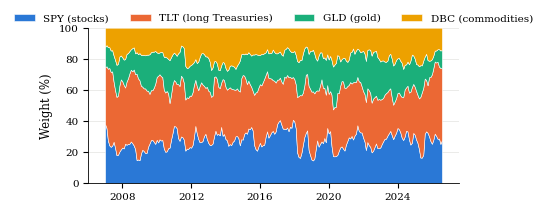

In [15]:
w = positions4.loc["rp_unconditional", ["SPY", "TLT", "GLD", "DBC"]]
w = w.div(w.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(WIDTH, 2.2))
ax.stackplot(w.index, 100 * w.T.to_numpy(), labels=["SPY (stocks)", "TLT (long Treasuries)", "GLD (gold)",
                                                     "DBC (commodities)"],
             colors=[BLUE, ORANGE, AQUA, YELLOW], lw=0.4, edgecolor="white")
ax.set_ylabel("Weight (%)")
ax.set_ylim(0, 100)
ax.legend(loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.15))
fig.tight_layout()
helpers.save_figure(fig, "fig_weights")

## Table 7 and Figure 8 - Forecasting the correlation (stage 5)

In [16]:
order5 = ["historical_mean", "last_month", "rolling_12m", "ols_all", "ridge_market", "ridge_all",
          "forest_market", "forest_all", "boosting_market", "boosting_all"]
acc = accuracy.loc["full sample"].loc[order5, ["rmse", "r2 vs mean", "r2 vs rolling", "p"]].copy()
sharpe5 = perf5.loc["full sample", "sharpe"]
gain = sharpe5["oracle_spy_tlt"] - sharpe5["rolling_12m"]
acc["sharpe"] = sharpe5.loc[order5]
acc["share"] = (sharpe5.loc[order5] - sharpe5["rolling_12m"]) / gain
oracle_row = pd.DataFrame({"rmse": [0.0], "r2 vs mean": [1.0], "r2 vs rolling": [1.0], "p": [np.nan],
                           "sharpe": [sharpe5["oracle_spy_tlt"]], "share": [1.0]}, index=["oracle_spy_tlt"])
acc = pd.concat([acc, oracle_row])
acc.loc["rolling_12m", ["r2 vs rolling", "p", "share"]] = [np.nan, np.nan, np.nan]
acc.index = [STRATEGY_NAMES[s] for s in acc.index]
save_latex(acc, "tab_forecast",
           {"rmse": "{:.3f}", "r2 vs mean": pct, "r2 vs rolling": pct, "p": pval, "sharpe": "{:.3f}",
            "share": lambda v: f"{100 * v:.0f}"},
           index_name="Forecast",
           col_names={"rmse": "RMSE", "r2 vs mean": "vs mean", "r2 vs rolling": "vs 12m",
                      "p": "DM $p$", "sharpe": "Sharpe", "share": r"Gain (\%)"},
           top=[("", 1), (r"$R^2_{OS}$ (\%)", 2), ("", 1), ("Portfolio", 2)],
           groups=[("Benchmarks", 0), ("Models", 3), ("Upper bound", 10)])
acc.round(3)

saved tables/tab_forecast.tex: 11 rows


,rmse,r2 vs mean,r2 vs rolling,p,sharpe,share
Historical mean,0.378,0.000,-0.470,0.002,0.663,-0.200
Last month,0.364,0.075,-0.360,0.003,0.675,-0.087
12-month average,0.312,0.320,NaN,NaN,0.684,NaN
Linear regression,0.321,0.282,-0.055,0.480,0.666,-0.176
"Ridge, market",0.307,0.342,0.033,0.537,0.679,-0.042
"Ridge, all",0.307,0.343,0.034,0.551,0.679,-0.051
"Random forest, market",0.305,0.352,0.048,0.420,0.693,0.085
"Random forest, all",0.303,0.358,0.056,0.322,0.695,0.108
"Boosting, market",0.315,0.308,-0.017,0.789,0.690,0.065
"Boosting, all",0.311,0.324,0.006,0.932,0.690,0.059


In [17]:
models = ["ridge_all", "forest_all", "boosting_all"]
by_period = pd.DataFrame({p: accuracy.loc[p].loc[models, "r2 vs rolling"] for p in
                          ["full sample", "2007-2016", "2017-2026", "2008", "2020", "2022"]})
by_period.index = [STRATEGY_NAMES[s] for s in by_period.index]
save_latex(by_period, "tab_forecast_periods", {c: pct for c in by_period.columns}, index_name="Model")
by_period.round(3)

saved tables/tab_forecast_periods.tex: 3 rows


,full sample,2007-2016,2017-2026,2008,2020,2022
"Ridge, all",0.034,0.115,-0.043,-0.598,0.225,-0.563
"Random forest, all",0.056,0.135,-0.019,-0.381,0.238,0.133
"Boosting, all",0.006,0.103,-0.087,-0.512,0.236,-0.202


PosixPath('/Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/figures/fig_forecasts.pdf')

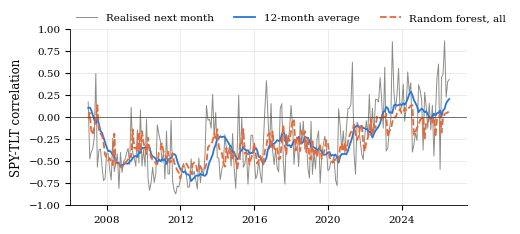

In [18]:
fig, ax = plt.subplots(figsize=(WIDTH, 2.4))
ax.plot(predictions.index, predictions["realised_next_month"], color=GREY, lw=0.7, label="Realised next month")
ax.plot(predictions.index, predictions["rolling_12m"], color=BLUE, lw=1.3, label="12-month average")
ax.plot(predictions.index, predictions["forest_all"], color=ORANGE, lw=1.3, ls="--", label="Random forest, all")
ax.axhline(0, color=DARK, lw=0.5)
ax.set_ylabel("SPY-TLT correlation")
ax.set_ylim(-1, 1)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.2, ncol=3)
fig.tight_layout()
helpers.save_figure(fig, "fig_forecasts")

## Figure 9 - What the models use

PosixPath('/Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/figures/fig_importance.pdf')

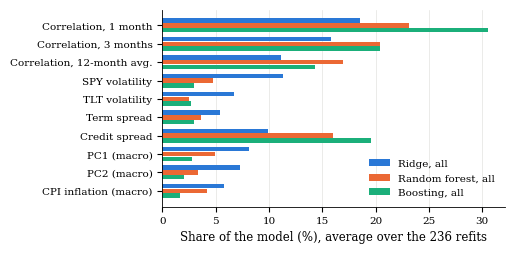

In [19]:
feat_names = {"corr_1m": "Correlation, 1 month", "corr_3m": "Correlation, 3 months",
              "corr_12m": "Correlation, 12-month avg.", "log_vol_spy": "SPY volatility",
              "log_vol_tlt": "TLT volatility", "term_spread": "Term spread", "credit_spread": "Credit spread",
              "pc1": "PC1 (macro)", "pc2": "PC2 (macro)", "inflation": "CPI inflation (macro)"}
imp = importance.drop(index="macro, total")[["ridge_all", "forest_all", "boosting_all"]].rename(index=feat_names)
y = np.arange(len(imp))
fig, ax = plt.subplots(figsize=(WIDTH, 2.6))
for j, (c, col) in enumerate(zip([BLUE, ORANGE, AQUA], imp.columns)):
    ax.barh(y + (j - 1) * 0.26, 100 * imp[col], height=0.24, color=c, label=STRATEGY_NAMES[col])
ax.set_yticks(y, imp.index)
ax.invert_yaxis()
ax.set_xlabel("Share of the model (%), average over the 236 refits")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
helpers.save_figure(fig, "fig_importance")

## Figure 10 - Sharpe ratios: what each forecast is worth in the portfolio

PosixPath('/Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/figures/fig_sharpe.pdf')

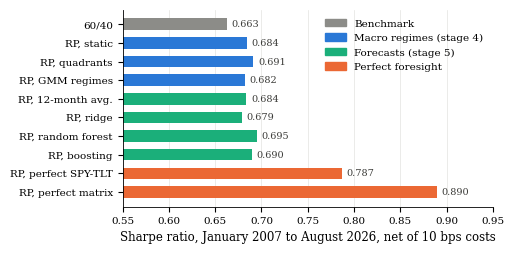

In [20]:
bars = pd.Series({
    "60/40": perf4.loc[("levered", "full sample", "60_40"), "sharpe"],
    "RP, static": perf4.loc[("levered", "full sample", "rp_unconditional"), "sharpe"],
    "RP, quadrants": perf4.loc[("levered", "full sample", "rp_quadrants"), "sharpe"],
    "RP, GMM regimes": perf4.loc[("levered", "full sample", "rp_gmm"), "sharpe"],
    "RP, 12-month avg.": sharpe5["rolling_12m"],
    "RP, ridge": sharpe5["ridge_all"],
    "RP, random forest": sharpe5["forest_all"],
    "RP, boosting": sharpe5["boosting_all"],
    "RP, perfect SPY-TLT": sharpe5["oracle_spy_tlt"],
    "RP, perfect matrix": perf4.loc[("levered", "full sample", "rp_oracle"), "sharpe"],
})
col = [GREY, BLUE, BLUE, BLUE, AQUA, AQUA, AQUA, AQUA, ORANGE, ORANGE]
fig, ax = plt.subplots(figsize=(WIDTH, 2.6))
yy = np.arange(len(bars))
ax.barh(yy, bars, color=col, height=0.62)
for i, v in enumerate(bars):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=7, color=DARK)
ax.set_yticks(yy, bars.index)
ax.invert_yaxis()
ax.set_xlim(0.55, 0.95)
ax.set_xlabel("Sharpe ratio, January 2007 to August 2026, net of 10 bps costs")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in [GREY, BLUE, AQUA, ORANGE]]
ax.legend(handles, ["Benchmark", "Macro regimes (stage 4)", "Forecasts (stage 5)", "Perfect foresight"],
          loc="upper right")
fig.tight_layout()
helpers.save_figure(fig, "fig_sharpe")

## Figure 11 - Realised volatility against the 10% target (rolling 12 months)

PosixPath('/Users/marcodamico/Desktop/hec/semestre 3/data science/Advanced_Data_Analytics/figures/fig_volatility.pdf')

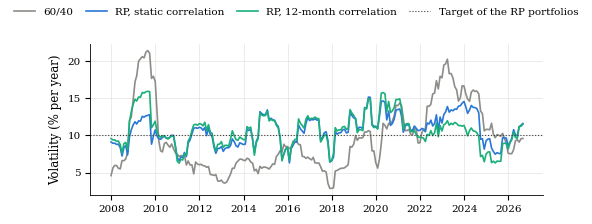

In [21]:
fig, ax = plt.subplots(figsize=(WIDTH, 2.2))
for s, (c, lab) in {"60_40": (GREY, "60/40"), "rp_unconditional": (BLUE, "RP, static correlation"),
                    "rp_rolling": (AQUA, "RP, 12-month correlation")}.items():
    ex = returns4[s] - rf.reindex(returns4.index)
    ax.plot(ex.index, 100 * ex.rolling(12).std() * np.sqrt(12), color=c, label=lab)
ax.axhline(10, color=DARK, lw=0.8, ls=":", label="Target of the RP portfolios")
ax.set_ylabel("Volatility (% per year)")
fig.legend(loc="upper center", ncol=4, borderaxespad=0.3, columnspacing=1.2)
fig.tight_layout(rect=(0, 0, 1, 0.89))
helpers.save_figure(fig, "fig_volatility")

## Table 8 - Do the regime labels keep their meaning between refits?

The checks of sections 2b.6 and 2c.4 of `03_regimes`, for the runs discussed in the paper.

In [22]:
stability = pd.concat([load("regimes_stability", index_col=[0, 1]), load("regimes_idx_stability", index_col=[0, 1])])
STAB_RUNS = [  # (label, run, method)
    ("PCA + GMM, $k=3$ (main)", "realtime_12m_k3", "gmm"),
    ("PCA + K-Means, $k=3$", "realtime_12m_k3", "kmeans"),
    ("PCA + GMM, $k=3$, revised", "revised_12m_k3", "gmm"),
    ("PCA + GMM, $k=4$", "realtime_12m_k4", "gmm"),
    ("Indices + GMM, $k=2$", "realtime_idx_k2", "gmm"),
    ("Indices + CPI level + GMM, $k=4$", "realtime_idx_cpi_k4", "gmm"),
]
stab = pd.DataFrame({label: stability.loc[(run, method)] for label, run, method in STAB_RUNS}).T
stab_out = stab[["refits", "renamed", "kept, mean", "kept, worst", "same label without matching"]].astype(float)
stab_out["worst refit"] = pd.to_datetime(stab["worst refit"]).dt.strftime("%b %Y")
stab_out = stab_out[["renamed", "kept, mean", "kept, worst", "worst refit", "same label without matching"]]
save_latex(stab_out, "tab_stability",
           {"renamed": "{:.0f}", "kept, mean": pct, "kept, worst": pct, "worst refit": "{}",
            "same label without matching": pct},
           index_name="Regimes (real time)",
           col_names={"renamed": "Renamed", "kept, mean": r"Mean (\%)", "kept, worst": r"Worst (\%)",
                      "worst refit": "Worst refit", "same label without matching": r"No fix (\%)"},
           top=[("", 1), ("Past months that keep their label", 3), ("", 1)])
print(open(config.TABLES / "tab_stability.tex").read())

saved tables/tab_stability.tex: 6 rows
\begin{tabular}{lrrrlr}
\toprule
 &  & \multicolumn{3}{c}{Past months that keep their label} &  \\
\cmidrule(lr){3-5}
Regimes (real time) & Renamed & Mean (\%) & Worst (\%) & Worst refit & No fix (\%) \\
\midrule
PCA + GMM, $k=3$ (main) & 21 & 96.8 & 27.3 & Mar 2009 & 38.4 \\
PCA + K-Means, $k=3$ & 0 & 99.6 & 76.5 & Jun 2009 & -- \\
PCA + GMM, $k=3$, revised & 2 & 98.1 & 64.9 & May 2007 & -- \\
PCA + GMM, $k=4$ & 6 & 94.8 & 38.5 & Aug 2009 & -- \\
Indices + GMM, $k=2$ & 23 & 99.4 & 60.0 & Jan 2001 & -- \\
Indices + CPI level + GMM, $k=4$ & 8 & 94.1 & 49.3 & Oct 2012 & -- \\
\bottomrule
\end{tabular}



## Check: every file is there

In [23]:
print(sorted(p.name for p in config.FIGURES.glob("*.pdf")))
print(sorted(p.name for p in config.TABLES.glob("*.tex")))

['fig_correlation.pdf', 'fig_forecasts.pdf', 'fig_importance.pdf', 'fig_loadings.pdf', 'fig_quadrant_timeline.pdf', 'fig_realtime_revised.pdf', 'fig_separation.pdf', 'fig_sharpe.pdf', 'fig_volatility.pdf', 'fig_wealth.pdf', 'fig_weights.pdf']
['tab_data.tex', 'tab_forecast.tex', 'tab_forecast_periods.tex', 'tab_portfolios.tex', 'tab_quadrants.tex', 'tab_robustness.tex', 'tab_separation.tex', 'tab_stability.tex', 'tab_subperiods.tex', 'tab_subperiods_sharpe.tex']
